# Motion planning under uncertainty
From the book *Bayesian Methods for Autonomous Robotics and Intelligent Infrastructure Systems* by Khalid M. Mosalam.

Companion to **Motion Planning Under Uncertainty**. All data are simulated.

Demo 1 compares belief ellipses and paths with **different mean costs (10.0 and 10.8)** and different variances. Demo 2 compares goal-only and information-gathering actions. Its distance metric is the distance from the **belief mean** to the goal.

Run top to bottom from this notebook directory. The risk tradeoff and Monte Carlo comparison are exported to `../figures/` as vector PDFs. Dependencies: NumPy and Matplotlib.

## Belief geometry and risk-sensitive path choice

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def cov_ellipse(P, n_std=2.0, n=200):
    # Eigen-decomposition for ellipse
    w, V = np.linalg.eigh(P)
    order = np.argsort(w)[::-1]
    w, V = w[order], V[:, order]
    t = np.linspace(0, 2*np.pi, n)
    circle = np.vstack([np.cos(t), np.sin(t)])
    axes = n_std * np.sqrt(w)
    E = (V @ (axes[:,None] * circle))
    return E[0,:], E[1,:]

def plot_beliefs(ax, mus, covs, labels=None, n_std=2.0):
    for i,(m,P) in enumerate(zip(mus,covs)):
        ex,ey = cov_ellipse(P, n_std=n_std)
        ax.plot(m[0] + ex, m[1] + ey)
        ax.plot(m[0], m[1], marker='o')
        if labels:
            ax.text(m[0]+0.05, m[1]+0.05, labels[i], fontsize=9)

np.random.seed(2)


### Belief-space geometry

A Gaussian belief $b\approx\mathcal{N}(\mu,\Sigma)$ can be drawn as a mean and covariance ellipse. The following illustrative beliefs use ellipses with `n_std=2.0`.

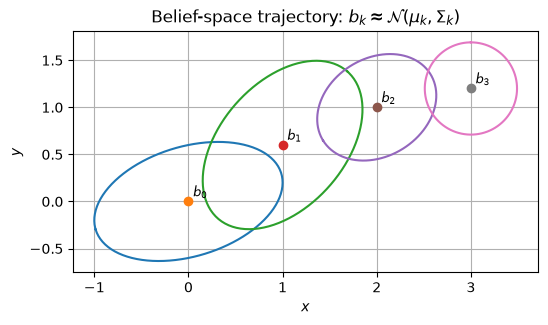

In [2]:
mus = [np.array([0.0, 0.0]),
       np.array([1.0, 0.6]),
       np.array([2.0, 1.0]),
       np.array([3.0, 1.2])]

covs = [np.array([[0.25, 0.05],[0.05, 0.10]]),
        np.array([[0.18, 0.08],[0.08, 0.20]]),
        np.array([[0.10, 0.02],[0.02, 0.08]]),
        np.array([[0.06, 0.00],[0.00, 0.06]])]

fig, ax = plt.subplots(figsize=(6,4))
plot_beliefs(ax, mus, covs, labels=[f"$b_{k}$" for k in range(len(mus))], n_std=2.0)
ax.set_aspect('equal', 'box')
ax.grid(True)
ax.set_xlabel("$x$")
ax.set_ylabel("$y$")
ax.set_title("Belief-space trajectory: $b_k \\approx \\mathcal{N}(\\mu_k,\\Sigma_k)$")
plt.show()


### Risk-neutral and risk-averse path choice

Path A has lower expected cost but higher variance: $E[c_A]=10.0$, $\operatorname{Var}(c_A)=9$. Path B has slightly higher expected cost and lower variance: $E[c_B]=10.8$, $\operatorname{Var}(c_B)=1.44$.

The objective is $J=E[c]+\lambda\operatorname{Var}(c)$. As $\lambda$ increases, the preferred path can switch from A to B. The synthetic samples below estimate the moments.

In [3]:
N = 20000

# Synthetic cost samples
cA = np.random.normal(loc=10.0, scale=3.0, size=N)   # riskier
cB = np.random.normal(loc=10.8, scale=1.2, size=N)   # safer

EA, VA = cA.mean(), cA.var()
EB, VB = cB.mean(), cB.var()
print("E[cA], Var[cA] =", EA, VA)
print("E[cB], Var[cB] =", EB, VB)


E[cA], Var[cA] = 9.998120626314783 9.075591502032113
E[cB], Var[cB] = 10.801586342924187 1.4383512309257793


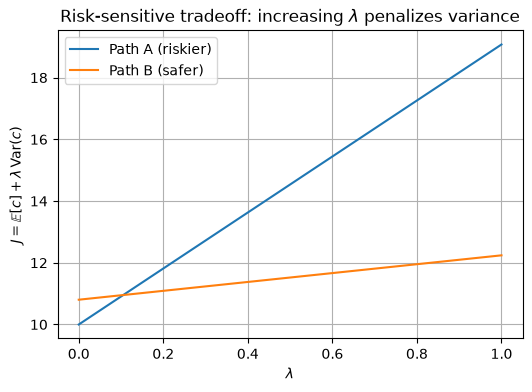

Switch to safer Path B at approximately lambda = 0.12


In [4]:
lambdas = np.linspace(0, 1.0, 51)
JA = EA + lambdas*VA
JB = EB + lambdas*VB

fig, ax = plt.subplots(figsize=(6,4))
ax.plot(lambdas, JA, label="Path A (riskier)")
ax.plot(lambdas, JB, label="Path B (safer)")
ax.set_xlabel("$\\lambda$")
ax.set_ylabel("$J = \\mathbb{E}[c] + \\lambda\\,\\mathrm{Var}(c)$")
ax.grid(True)
ax.set_title("Risk-sensitive tradeoff: increasing $\\lambda$ penalizes variance")
ax.legend()
fig.savefig("../figures/motion-planning-risk-tradeoff.pdf", bbox_inches="tight",
            metadata={"CreationDate": None, "ModDate": None})
plt.show()

idx = np.where(JB < JA)[0]
if len(idx) > 0:
    lam_star = lambdas[idx[0]]
    print("Switch to safer Path B at approximately lambda =", lam_star)
else:
    print("No switch for lambda in [0,1].")


The reported switch is the first point on a grid spaced by 0.02, using sample moments. The book's analytic threshold, about 0.1058, uses the population moments.

### Synthetic cost distributions

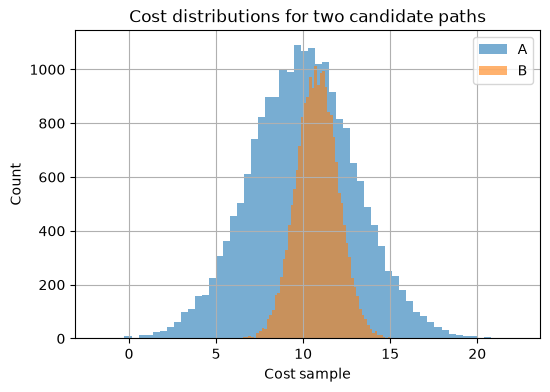

In [5]:
fig, ax = plt.subplots(figsize=(6,4))
ax.hist(cA, bins=60, alpha=0.6, label="A")
ax.hist(cB, bins=60, alpha=0.6, label="B")
ax.set_xlabel("Cost sample")
ax.set_ylabel("Count")
ax.grid(True)
ax.set_title("Cost distributions for two candidate paths")
ax.legend()
plt.show()


## Information-gathering actions

A toy 2D robot has state $\mathbf{x}=[x,y]^\top$ and observes the range to one beacon: $z=\|\mathbf{x}-\ell\|+v$, with $v\sim\mathcal{N}(0,\sigma^2)$. An EKF-style update maintains the belief $(\mu,\Sigma)$.

The robot can move toward the goal or choose among eight directions using expected covariance reduction and progress. This is a toy policy comparison, with no measured data or obstacle model.

In [6]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(1)


In [7]:
def h(mu, l):
    return np.sqrt((mu[0]-l[0])**2 + (mu[1]-l[1])**2)

def H_jac(mu, l):
    dx = mu[0]-l[0]
    dy = mu[1]-l[1]
    r = np.sqrt(dx*dx + dy*dy) + 1e-12
    return np.array([[dx/r, dy/r]])  # 1x2

def ekf_update(mu, P, z, l, sigma):
    H = H_jac(mu, l)          # 1x2
    y = z - h(mu, l)          # innovation
    S = H @ P @ H.T + sigma**2
    K = (P @ H.T) / S         # 2x1
    mu2 = mu + (K.flatten()*y)
    P2 = (np.eye(2) - K @ H) @ P
    return mu2, P2

def step_toward(mu, target, step=0.2):
    d = target - mu
    n = np.linalg.norm(d) + 1e-12
    return mu + step*(d/n)

def expected_trace_after_move(mu, P, l, sigma, u, Q):
    # Predict
    mu_p = mu + u
    P_p = P + Q
    # Expected posterior trace using linearized EKF update (measurement depends on mu_p)
    H = H_jac(mu_p, l)
    S = H @ P_p @ H.T + sigma**2
    K = (P_p @ H.T) / S
    P_post = (np.eye(2) - K @ H) @ P_p
    return np.trace(P_post)

def choose_action(mu, P, goal, l, sigma, step=0.2, Q=None, mode="goal", w_info=1.0):
    if Q is None:
        Q = 0.01*np.eye(2)

    # Candidate actions (8 directions)
    dirs = np.array([[1,0],[0,1],[-1,0],[0,-1],[1,1],[-1,1],[-1,-1],[1,-1]], dtype=float)
    dirs = dirs / np.linalg.norm(dirs, axis=1)[:,None]
    U = step*dirs

    if mode == "goal":
        # greedy toward goal
        u = step_toward(mu, goal, step=step) - mu
        return u, {"mode":"goal"}

    # info-gathering: minimize a weighted combination of expected covariance and goal distance
    best = None
    best_u = None
    for u in U:
        tr = expected_trace_after_move(mu, P, l, sigma, u, Q)
        dist = np.linalg.norm((mu+u) - goal)
        score = tr*w_info + dist  # simple tradeoff
        if best is None or score < best:
            best = score
            best_u = u
    return best_u, {"mode":"info", "score":best}


### One simulated run per policy

Information gathering minimizes the proxy score $w_{\rm info}\operatorname{tr}(\Sigma^+(u))+\|\mu+u-x_{\rm goal}\|$, using the expected posterior covariance after moving and taking a range measurement. The goal-distance term uses the predicted belief mean.

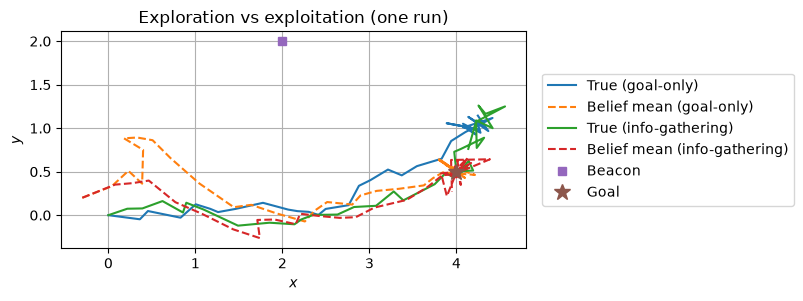

In [8]:
def simulate(policy, T=35, step=0.2, w_info=2.0):
    # World
    l = np.array([2.0, 2.0])      # beacon
    goal = np.array([4.0, 0.5])   # goal
    sigma = 0.10
    Q = 0.01*np.eye(2)

    # True state and belief
    x = np.array([0.0, 0.0])
    mu = np.array([-0.3, 0.2])
    P  = np.array([[0.5, 0.0],[0.0, 0.5]])

    xs=[x.copy()]; mus=[mu.copy()]; traces=[np.trace(P)]
    for k in range(T):
        if policy=="goal":
            u, _ = choose_action(mu, P, goal, l, sigma, step=step, Q=Q, mode="goal")
        else:
            u, _ = choose_action(mu, P, goal, l, sigma, step=step, Q=Q, mode="info", w_info=w_info)

        # True motion (with small disturbance)
        x = x + u + np.random.multivariate_normal(mean=[0,0], cov=Q)

        # Belief predict
        mu = mu + u
        P  = P + Q

        # Measurement
        z = np.linalg.norm(x - l) + np.random.normal(0, sigma)

        # Update
        mu, P = ekf_update(mu, P, z, l, sigma)

        xs.append(x.copy()); mus.append(mu.copy()); traces.append(np.trace(P))
    return np.array(xs), np.array(mus), np.array(traces), l, goal

xs_g, mus_g, tr_g, l, goal = simulate("goal")
xs_i, mus_i, tr_i, _, _ = simulate("info", w_info=2.0)

fig, ax = plt.subplots(figsize=(6,4))
ax.plot(xs_g[:,0], xs_g[:,1], label="True (goal-only)")
ax.plot(mus_g[:,0], mus_g[:,1], "--", label="Belief mean (goal-only)")
ax.plot(xs_i[:,0], xs_i[:,1], label="True (info-gathering)")
ax.plot(mus_i[:,0], mus_i[:,1], "--", label="Belief mean (info-gathering)")
ax.plot(l[0], l[1], "s", label="Beacon")
ax.plot(goal[0], goal[1], "*", markersize=12, label="Goal")
ax.set_aspect('equal','box')
ax.grid(True)
ax.set_xlabel("$x$")
ax.set_ylabel("$y$")
ax.set_title("Exploration vs exploitation (one run)")
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.show()


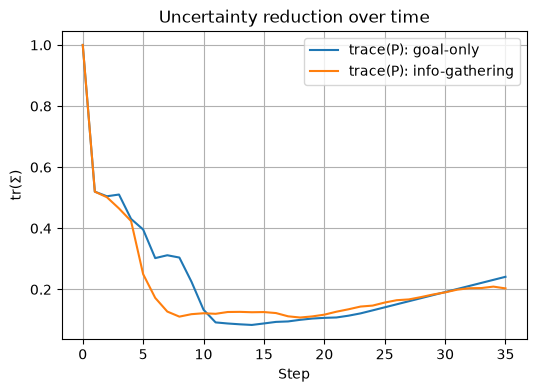

In [9]:
fig, ax = plt.subplots(figsize=(6,4))
ax.plot(tr_g, label="trace(P): goal-only")
ax.plot(tr_i, label="trace(P): info-gathering")
ax.grid(True)
ax.set_xlabel("Step")
ax.set_ylabel(r"$\mathrm{tr}(\Sigma)$")
ax.set_title("Uncertainty reduction over time")
ax.legend()
plt.show()


### Monte Carlo comparison

Repeat each policy 200 times. Report the final covariance trace and the **distance from the final belief mean to the goal**. This distance does not measure the true robot position's distance to the goal.

In [10]:
def monte_carlo(M=200, w_info=2.0):
    fin = {"goal":[], "info":[]}
    for _ in range(M):
        xs_g, mus_g, tr_g, l, goal = simulate("goal")
        xs_i, mus_i, tr_i, _, _ = simulate("info", w_info=w_info)
        fin["goal"].append([tr_g[-1], np.linalg.norm(mus_g[-1]-goal)])
        fin["info"].append([tr_i[-1], np.linalg.norm(mus_i[-1]-goal)])
    return np.array(fin["goal"]), np.array(fin["info"])

G,I = monte_carlo(M=200, w_info=2.0)

print("Goal-only:   mean final trace(P) =", G[:,0].mean(), "mean final distance from belief mean to goal =", G[:,1].mean())
print("Info-gather: mean final trace(P) =", I[:,0].mean(), "mean final distance from belief mean to goal =", I[:,1].mean())


Goal-only:   mean final trace(P) = 0.2482854674991512 mean final distance from belief mean to goal = 0.12455151737769642
Info-gather: mean final trace(P) = 0.22739164221136277 mean final distance from belief mean to goal = 0.14772657670383615


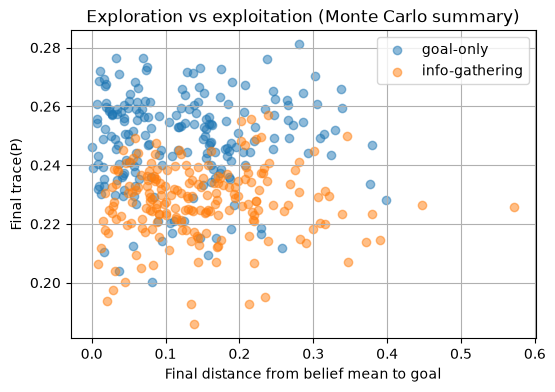

In [11]:
fig, ax = plt.subplots(figsize=(6,4))
ax.scatter(G[:,1], G[:,0], alpha=0.5, label="goal-only")
ax.scatter(I[:,1], I[:,0], alpha=0.5, label="info-gathering")
ax.set_xlabel("Final distance from belief mean to goal")
ax.set_ylabel("Final trace(P)")
ax.grid(True)
ax.set_title("Exploration vs exploitation (Monte Carlo summary)")
ax.legend()
fig.savefig("../figures/motion-planning-information-tradeoff.pdf", bbox_inches="tight",
            metadata={"CreationDate": None, "ModDate": None})
plt.show()
